In [8]:
import os
import random 
import numpy as np
import pandas as pd
import zarr
import dask.array as da
from importlib import reload
from whole_embryo_analysis.align_3d import align_object_skew
from aicsshparam.shtools import get_mesh_from_image

In [16]:
from whole_embryo_analysis.utils import madi_utils
root = "/net/beliveau/vol2/instrument/E9.5_299/Zoom_299"
mask_path = f"{root}/dataset_fused_masks_Julia_FT.zarr"
image_path = f"{root}/dataset_fused_rechunked_blocks.zarr"
bbox_path = f"{root}/dataset_fused_features-JGseg-030926_align_skew_bboxes.csv"
df_path = f"{root}/dataset_fused_features-JGseg-030926_align_skew.csv"

dir_save = f"{root}/analysis_pipeline/"

channels = [0, 1, 2]
mask_da, image_arrays = madi_utils.load_data(mask_path, image_path, channels)

print(f"Mask shape: {mask_da.shape}")
print(f"Available channels: {list(image_arrays.keys())}")
for ch, arr in image_arrays.items():    print(f"Channel {ch} shape: {arr.shape}")

Mask shape: (3848, 8173, 7157)
Available channels: [0, 1, 2]
Channel 0 shape: (3848, 8173, 7157)
Channel 1 shape: (3848, 8173, 7157)
Channel 2 shape: (3848, 8173, 7157)


In [17]:
# VISUALIZE SPECIFIC OBJECT BY NUCLEAR ID
# aligned_skew, original_list = [], []
# label = 491516

# df_bboxes = pd.read_csv(bbox_path)
# df_bboxes = madi_utils.add_chunk_indices(df_bboxes, mask_da.chunks)
# df_bboxes = df_bboxes[df_bboxes["label"] == label]
# zstart, zend, ystart, yend, xstart, xend = madi_utils.get_bounds(df_bboxes)
# mask_roi = mask_da[zstart:zend, ystart:yend, xstart:xend]

# grouped = df_bboxes.groupby(["cz", "cy", "cx"], sort=False)
# group_items = list(grouped)

# RANDOM SELECTED OBJECT - comment in below this line and comment out above to run random object
n=1
aligned_skew, original_list = [], []
random.seed(123456)

df_bboxes = pd.read_csv(bbox_path)
df_bboxes = madi_utils.add_chunk_indices(df_bboxes, mask_da.chunks)

grouped = df_bboxes.groupby(["cz", "cy", "cx"], sort=False)
group_items = list(grouped)

(cz, cy, cx), group_df = random.choice(group_items)
labels = group_df["label"].astype(np.int64).tolist()

zstart, zend, ystart, yend, xstart, xend = madi_utils.get_bounds(group_df)
mask_roi = mask_da[zstart:zend, ystart:yend, xstart:xend]
label = np.random.choice(labels, size=n)[0]

print(zstart, zend)

1520 2048


Label:  694369


2026-08-11 14:59:30.434 (7995.819s) [        59B07740]            Contour.cxx:49    INFO| Using flying edges


obj num bytes: 758051712


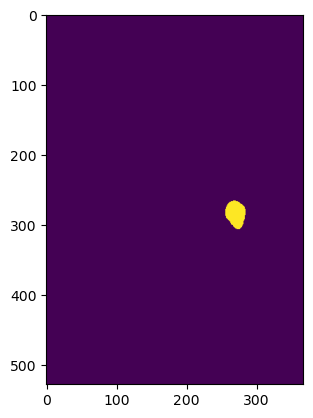

In [18]:
print("Label: ", label)
# add original object to list
import matplotlib.pyplot as plt 
def get_object(obj_id, mask_roi):
    obj_image = np.where(mask_roi == obj_id, 1, 0)
    obj_image = obj_image.compute()
    plt.imshow(np.max(obj_image, axis=1))
    mesh, _, _ = get_mesh_from_image(obj_image)
    return mesh, obj_image

og_mesh, obj_image = get_object(label, mask_roi)
print(f"obj num bytes: {obj_image.nbytes}")
original_list.append((og_mesh, obj_image))

In [19]:
# # add aligned object to list
aligned_image, _ = align_object_skew(obj_image, {})
aligned_mesh, _, _ = get_mesh_from_image(aligned_image)

2026-08-11 14:59:58.154 (8023.539s) [        59B07740]            Contour.cxx:49    INFO| Using flying edges


In [21]:
aligned_skew.append((aligned_mesh, aligned_image))
dir = "/net/beliveau/vol2/instrument/E9.5_299/Zoom_299/analysis_pipeline"
def plot_reconstruction(obj_id, title, dir, coeffs, show_title=False, lmax=16):
    mat = madi_utils.get_coeffs(obj_id, coeffs)  # Fixed function name
    mesh_rec, img_rec = madi_utils.reconstruct(mat, lrec=lmax)
    rec_tuple = (mesh_rec, img_rec)
    madi_utils.plot_object(rec_tuple, title, dir, show_title=show_title, save_image=True)    
    return mesh_rec

def plot_list(original_list, aligned_list, obj_id, df):
    for og, std in zip(original_list, aligned_list):
        madi_utils.plot_object(og, f"Before Alignment {obj_id}", dir=dir, show_title=True, save_image=True)
        madi_utils.plot_object(std, f"After Alignment {obj_id}", dir=dir, show_title=True, save_image=True)
        plot_reconstruction(obj_id, 
        f"Reconstruction {obj_id}", dir=dir, coeffs=df ,show_title=True)
plot_list(original_list, aligned_skew, label, df=df_path)